# Problema 1 — Inciso (d): intervención por umbrales y costo de equidad

Esta libreta implementa la intervención del inciso (d) y evalúa cinco
definiciones de equidad. Parte de los resultados ya producidos:

- `resultados/split_indices.csv`: split 70/30 autoritativo.
- `resultados/03_resumen_modelos.csv`: mejor modelo e hiperparámetros.
- `resultados/04_probabilidades_calibradas_test.csv`: probabilidades
  calibradas del 30% de prueba.
- `resultados/04_metodo_calibracion.csv`: método de calibración elegido.

Reglas que respeta:

- **Ganancia del banco:** `+G` por cada aprobado que paga, `-L` por cada
  aprobado que incumple y `0` por cada rechazado. Se aprueba cuando
  `score < umbral` y se rechaza cuando `score >= umbral`.
- **Línea base:** un único umbral `1/6` para todos.
- **`SEX` solo como auditoría:** no entra al modelo ni al calibrador; se usa
  para separar hombres (`SEX=1`) y mujeres (`SEX=2`).
- **Selección sin fuga:** los umbrales por grupo se eligen con predicciones
  fuera de muestra (`cross_val_predict`, `cv=5`) sobre el 70%. El 30% de
  prueba se usa una sola vez para reportar el resultado, no para afinar los
  umbrales.
- **Definiciones evaluadas:** paridad demográfica, igual `FPR`, igual `FNR`,
  igual `FPR` y `FNR`, y paridad predictiva (igual `PPV`).
- **Hipótesis de trabajo:** igual `FPR`, porque el bootstrap de
  `05_tabla_grupos` mostró que la diferencia `FPR_H − FPR_M` no contiene el
  cero, mientras que la de `FNR` sí. La tabla comparativa decide; si otra
  definición resultara claramente mejor, se justifica.
- **Bootstrap:** 2,000 réplicas con la semilla `SEED` para el intervalo del
  95% de la diferencia de `FPR` después de intervenir.

In [1]:
"""Configuración, rutas e importaciones de la libreta."""

from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import cross_val_predict


def _buscar_raiz(inicio: Path) -> Path:
    """Sube desde el directorio actual hasta encontrar la raíz del repo.

    La raíz se reconoce porque contiene `common.py` y la carpeta `problema-1/`.
    Así la libreta funciona igual si se abre desde la raíz o desde
    `problema-1/`, y también cuando la ejecuta `nbconvert`.
    """
    for base in [inicio, *inicio.parents]:
        if (base / "common.py").exists() and (base / "problema-1").is_dir():
            return base
    return inicio


_AQUI = Path.cwd()
_RAIZ = _buscar_raiz(_AQUI)
_DIR_PROBLEMA = _RAIZ / "problema-1" if (_RAIZ / "problema-1").is_dir() else _RAIZ

# Permite importar common.py (raíz) y los módulos de problema-1/.
for _ruta in (_RAIZ, _DIR_PROBLEMA):
    if str(_ruta) not in sys.path:
        sys.path.insert(0, str(_ruta))

from common import G, L, SEED, UMBRAL  # noqa: E402
from data import TARGET, cargar_dataframe  # noqa: E402
import equidad as eq  # noqa: E402
import evidencia_datos as ev  # noqa: E402
import modelos as mo  # noqa: E402

RESULTADOS = _RAIZ / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", None)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# Cuadrícula de umbrales que pide el inciso: 0.05 a 0.60 con paso 0.01.
UMBRALES = np.round(np.arange(0.05, 0.601, 0.01), 2)
# Tolerancia máxima de la diferencia entre grupos para considerar una
# definición de equidad como satisfecha.
TOLERANCIA = 0.01
# Número de réplicas bootstrap que pide el inciso.
N_BOOTSTRAP = 2000
# Definición de equidad elegida por la hipótesis de trabajo.
DEFINICION_ELEGIDA = "igual_fpr"

print(f"SEED = {SEED}")
print(f"G = {G}, L = {L}, UMBRAL = G/(G+L) = {UMBRAL:.12f}")
print(f"Cuadrícula de umbrales: {UMBRALES[0]:.2f} a {UMBRALES[-1]:.2f}, "
      f"paso {UMBRALES[1] - UMBRALES[0]:.2f}, {len(UMBRALES)} valores.")
print(f"Tolerancia de equidad = {TOLERANCIA}")
print(f"Réplicas bootstrap = {N_BOOTSTRAP}")
print(f"Directorio de resultados = {RESULTADOS}")

SEED = 223210350
G = 1, L = 5, UMBRAL = G/(G+L) = 0.166666666667
Cuadrícula de umbrales: 0.05 a 0.60, paso 0.01, 56 valores.
Tolerancia de equidad = 0.01
Réplicas bootstrap = 2000
Directorio de resultados = /home/tito/repos/RDP/Examen_1_RDP/resultados


## 1. Carga, validación y probabilidades fuera de muestra del 70%

Primero se cargan el dataset, el split y el mejor modelo. Se reconstruye el
`Pipeline` sin `SEX` y se comprueba que reproduce las probabilidades que
guardó `04_calibracion`. Después se calculan las probabilidades **fuera de
muestra** del 70% con el mismo esquema de calibración anidada del inciso
(b): en cada partición externa se ajusta `CalibratedClassifierCV(cv=5)` con
el 80% interno y se predice el 20% externo.

Esas predicciones OOF son las que se usan para buscar los umbrales. El 30%
de prueba no participa en la búsqueda.

In [2]:
ruta_split = RESULTADOS / "split_indices.csv"
ruta_resumen = RESULTADOS / "03_resumen_modelos.csv"
ruta_probabilidades = RESULTADOS / "04_probabilidades_calibradas_test.csv"
ruta_metodo = RESULTADOS / "04_metodo_calibracion.csv"

for ruta in (ruta_split, ruta_resumen, ruta_probabilidades, ruta_metodo):
    if not ruta.exists():
        raise FileNotFoundError(
            f"No existe {ruta}. Ejecuta primero las libretas 02, 03 y 04."
        )

df = cargar_dataframe()
columnas_pay = mo.obtener_columnas_pay(df)
idx_train, idx_test = ev.cargar_indices(ruta_split, df, TARGET)

# El split guardado debe coincidir con el split reproducible de SEED.
idx_train_esperado, idx_test_esperado = ev.dividir_estratificado(
    df, TARGET, test_size=0.30, seed=SEED
)
if not (
    np.array_equal(idx_train, idx_train_esperado)
    and np.array_equal(idx_test, idx_test_esperado)
):
    raise ValueError(
        "El split guardado no coincide con el split reproducible de SEED. "
        "Revisa resultados/split_indices.csv antes de continuar."
    )

resumen = pd.read_csv(ruta_resumen)
mejor = resumen.loc[resumen["mejor_por_auc_cv"] == "sí"].iloc[0]
tabla_metodo = pd.read_csv(ruta_metodo)
metodo_calibracion = str(tabla_metodo.loc[0, "metodo_calibracion"])
if metodo_calibracion not in {"sin_calibrar", "sigmoid", "isotonic"}:
    raise ValueError(
        f"Método de calibración desconocido: '{metodo_calibracion}'."
    )

columnas_x = mo.columnas_entrada(df, TARGET, incluir_sexo=False)
if "SEX" in columnas_x:
    raise ValueError("SEX no debe estar en las columnas de entrada del modelo.")

X_train = df.iloc[idx_train][columnas_x].reset_index(drop=True)
y_train = df.iloc[idx_train][TARGET].reset_index(drop=True)
X_test = df.iloc[idx_test][columnas_x].reset_index(drop=True)
y_test = df.iloc[idx_test][TARGET].reset_index(drop=True).to_numpy(dtype=int)
sexo_train = df.iloc[idx_train]["SEX"].to_numpy(dtype=int)
sexo_test = df.iloc[idx_test]["SEX"].to_numpy(dtype=int)

# Reconstruimos el Pipeline del mejor modelo y verificamos que reproduzca las
# probabilidades sin calibrar que guardó 03_modelos.
pipeline_mejor = mo.construir_pipeline_desde_mejor(
    mejor, columnas_pay, seed=SEED, incluir_sexo=False
)
pipeline_mejor.fit(X_train, y_train)

tabla_probabilidades = pd.read_csv(ruta_probabilidades)
if not np.array_equal(tabla_probabilidades["indice"].to_numpy(), idx_test):
    raise ValueError(
        "Los índices de 04_probabilidades_calibradas_test.csv no coinciden "
        "con el split."
    )
if not np.array_equal(
    tabla_probabilidades["objetivo"].to_numpy(), y_test
):
    raise ValueError(
        "La columna 'objetivo' de 04_probabilidades_calibradas_test.csv no "
        "coincide con el dataset."
    )
if not np.array_equal(
    tabla_probabilidades["SEX"].to_numpy(), sexo_test
):
    raise ValueError(
        "La columna 'SEX' de 04_probabilidades_calibradas_test.csv no "
        "coincide con el dataset."
    )

prob_test_sin_calibrar = tabla_probabilidades[
    "prob_sin_calibrar"
].to_numpy(dtype=float)
prob_reconstruida = pipeline_mejor.predict_proba(X_test)[:, 1]
diferencia_reconstruccion = float(
    np.max(np.abs(prob_reconstruida - prob_test_sin_calibrar))
)
if diferencia_reconstruccion > 1e-7:
    raise ValueError(
        "El modelo reconstruido no reproduce las probabilidades de "
        f"03_modelos (diferencia máxima = {diferencia_reconstruccion:.2e})."
    )

if metodo_calibracion == "sin_calibrar":
    columna_probabilidad = "prob_sin_calibrar"
    prob_test = tabla_probabilidades[columna_probabilidad].to_numpy(dtype=float)
    estimador_oof = pipeline_mejor
else:
    columna_probabilidad = "prob_calibrada"
    prob_test = tabla_probabilidades[columna_probabilidad].to_numpy(dtype=float)
    estimador_oof = CalibratedClassifierCV(
        estimator=pipeline_mejor,
        method=metodo_calibracion,
        cv=5,
        n_jobs=1,
        ensemble=True,
    )

# Predicciones fuera de muestra del 70%: cada pliegue externo ajusta su propio
# calibrador con el 80% interno. Así ningún umbral se elige con datos que el
# modelo ya vio.
folds = ev.crear_folds(X_train, y_train, n_splits=5, seed=SEED)
oof = cross_val_predict(
    estimador_oof,
    X_train,
    y_train,
    cv=folds,
    method="predict_proba",
    n_jobs=1,
)[:, 1]

print(f"Mejor modelo: {mejor['modelo']} ({mejor['modelo_id']}).")
print(f"Método de calibración: {metodo_calibracion}.")
print(f"Columna de prueba usada: {columna_probabilidad}.")
print(f"Diferencia máxima de reconstrucción: {diferencia_reconstruccion:.2e}.")
print(f"Filas de entrenamiento: {len(X_train)}; filas de prueba: {len(X_test)}.")
print(
    "OOF del 70%: AUC = "
    f"{roc_auc_score(y_train, oof):.6f}, log-loss = "
    f"{log_loss(y_train, oof):.6f}, media = {oof.mean():.6f}, "
    f"tasa real = {y_train.mean():.6f}."
)

Mejor modelo: HistGradientBoostingClassifier (hist_gb).
Método de calibración: isotonic.
Columna de prueba usada: prob_calibrada.
Diferencia máxima de reconstrucción: 5.00e-09.
Filas de entrenamiento: 21000; filas de prueba: 9000.
OOF del 70%: AUC = 0.781927, log-loss = 0.426337, media = 0.221203, tasa real = 0.221190.


La reconstrucción del modelo coincide con las probabilidades guardadas y el
OOF conserva la calibración global: su media (`0.221203`) es prácticamente
la tasa real de incumplimiento del 70% (`0.221190`). Esto importa porque la
regla de decisión `s < G/(G+L)` supone que `s` es una probabilidad calibrada
de incumplimiento. El OOF es la única base admisible para buscar umbrales:
la prueba queda reservada para reportar el resultado.

## 2. Línea base con un solo umbral `1/6`

La línea base es la política actual del banco: aprobar si `score < 1/6` y
rechazar en caso contrario, sin distinguir grupos. Se calcula la tabla por
grupo en el 70% (OOF) y en el 30% de prueba. La ganancia se expresa en
unidades de `G` y por solicitante.

In [3]:
tabla_base_test, avisos_base_test = eq.tabla_grupos(
    y_test, prob_test, sexo_test, umbral=UMBRAL
)
tabla_base_oof, avisos_base_oof = eq.tabla_grupos(
    y_train.to_numpy(), oof, sexo_train, umbral=UMBRAL
)

columnas_tabla = [
    "grupo",
    "n",
    "p_g",
    "tasa_rechazo",
    "PPV",
    "FPR",
    "FNR",
    "TP",
    "FN",
    "FP",
    "TN",
    "ganancia",
    "ganancia_por_solicitante",
]
print("Línea base en el 30% de prueba (umbral único 1/6):")
display(tabla_base_test[columnas_tabla].round(6))
print("Línea base en el 70% (OOF, umbral único 1/6):")
display(tabla_base_oof[columnas_tabla].round(6))

tabla_base_test[columnas_tabla].to_csv(
    RESULTADOS / "06_tabla_base_test.csv", index=False, float_format="%.8f"
)
tabla_base_oof[columnas_tabla].to_csv(
    RESULTADOS / "06_tabla_base_oof.csv", index=False, float_format="%.8f"
)

ganancia_base_test = float(
    tabla_base_test.loc[
        tabla_base_test["grupo"] == eq.GRUPO_TODOS, "ganancia"
    ].iloc[0]
)
ganancia_base_oof = float(
    tabla_base_oof.loc[
        tabla_base_oof["grupo"] == eq.GRUPO_TODOS, "ganancia"
    ].iloc[0]
)
print(f"Ganancia base en prueba: {ganancia_base_test:.0f} unidades de G "
      f"({ganancia_base_test / len(y_test):.6f} por solicitante).")
print(f"Ganancia base OOF: {ganancia_base_oof:.0f} unidades de G "
      f"({ganancia_base_oof / len(y_train):.6f} por solicitante).")
if avisos_base_test or avisos_base_oof:
    print("AVISOS de división entre cero:")
    for aviso in [*avisos_base_test, *avisos_base_oof]:
        print(f"  - {aviso}")
else:
    print("Sin divisiones entre cero en la línea base.")

Línea base en el 30% de prueba (umbral único 1/6):


,grupo,n,p_g,tasa_rechazo,PPV,FPR,FNR,TP,FN,FP,TN,ganancia,ganancia_por_solicitante
0,Hombres (SEX=1),3584,0.232980,0.456473,0.382641,0.367406,0.250299,626,209,1010,1739,694.0,0.193638
1,Mujeres (SEX=2),5416,0.213442,0.410635,0.377248,0.325117,0.274221,839,317,1385,2875,1290.0,0.238183
2,Todos,9000,0.221222,0.428889,0.379534,0.341704,0.264189,1465,526,2395,4614,1984.0,0.220444


Línea base en el 70% (OOF, umbral único 1/6):


,grupo,n,p_g,tasa_rechazo,PPV,FPR,FNR,TP,FN,FP,TN,ganancia,ganancia_por_solicitante
0,Hombres (SEX=1),8304,0.245424,0.436175,0.414964,0.338174,0.262512,1503,535,2119,4147,1472.0,0.177264
1,Mujeres (SEX=2),12696,0.205340,0.400992,0.370261,0.317772,0.276947,1885,722,3206,6883,3273.0,0.257798
2,Todos,21000,0.221190,0.414905,0.388844,0.325589,0.270614,3388,1257,5325,11030,4745.0,0.225952


Ganancia base en prueba: 1984 unidades de G (0.220444 por solicitante).
Ganancia base OOF: 4745 unidades de G (0.225952 por solicitante).
Sin divisiones entre cero en la línea base.


La línea base reproduce la tabla del inciso (c): los hombres tienen mayor
tasa real de incumplimiento (`0.232980` frente a `0.213442`), mayor tasa de
rechazo (`0.456473` frente a `0.410635`) y mayor `FPR` (`0.367406` frente a
`0.325117`). La `PPV` es casi igual (`0.382641` y `0.377248`). La ganancia
total de prueba es `1984` unidades de `G` (`0.220444` por solicitante), y la
del OOF es la referencia contra la que se medirá el costo de la intervención.

## 3. Las cinco definiciones de equidad

Para cada definición se busca el par `(t_H, t_M)` que **maximiza la ganancia
total OOF** sujeto a que la diferencia de la métrica correspondiente sea
`<= 0.01` en valor absoluto. Las definiciones son:

- **Paridad demográfica:** misma tasa de rechazo.
- **Igual `FPR`:** misma fracción de no incumplidores rechazados.
- **Igual `FNR`:** misma fracción de incumplidores aprobados.
- **Igual `FPR` y `FNR`:** ambas diferencias dentro de la tolerancia.
- **Paridad predictiva:** misma `PPV`.

El par se elige **solo con OOF**. Después se aplica al 30% de prueba y se
reporta lo que ocurre; la prueba no se usa para corregir ni reordenar la
elección.

In [4]:
tabla_umbrales = eq.tabla_umbrales_por_grupo(
    y_train.to_numpy(), oof, sexo_train, UMBRALES
)

filas_comparativa = []
pares_por_definicion: dict[str, pd.DataFrame] = {}
for definicion, metricas_definicion in eq.DEFINICIONES.items():
    pares = eq.tabla_pares_umbrales(
        tabla_umbrales, metricas_definicion, tolerancia=TOLERANCIA
    )
    pares_por_definicion[definicion] = pares
    elegido = eq.seleccionar_par(pares)
    fila: dict[str, float | int | str] = {
        "definicion_id": definicion,
        "definicion": eq.ETIQUETAS_DEFINICION[definicion],
        "metricas_igualadas": " y ".join(metricas_definicion),
    }
    if elegido is None:
        fila.update(
            {
                "factible": "no",
                "t_H": np.nan,
                "t_M": np.nan,
                "ganancia_oof": np.nan,
                "max_abs_diff_oof": np.nan,
            }
        )
        filas_comparativa.append(fila)
        continue

    t_h = float(elegido["t_H"])
    t_m = float(elegido["t_M"])
    tabla_oof_def, _ = eq.tabla_grupos_umbrales(
        y_train.to_numpy(), oof, sexo_train, t_h, t_m
    )
    tabla_test_def, _ = eq.tabla_grupos_umbrales(
        y_test, prob_test, sexo_test, t_h, t_m
    )
    h_oof = tabla_oof_def.loc[
        tabla_oof_def["grupo"] == eq.GRUPO_HOMBRES
    ].iloc[0]
    m_oof = tabla_oof_def.loc[
        tabla_oof_def["grupo"] == eq.GRUPO_MUJERES
    ].iloc[0]
    total_oof = tabla_oof_def.loc[
        tabla_oof_def["grupo"] == eq.GRUPO_TODOS
    ].iloc[0]
    h_test = tabla_test_def.loc[
        tabla_test_def["grupo"] == eq.GRUPO_HOMBRES
    ].iloc[0]
    m_test = tabla_test_def.loc[
        tabla_test_def["grupo"] == eq.GRUPO_MUJERES
    ].iloc[0]
    total_test = tabla_test_def.loc[
        tabla_test_def["grupo"] == eq.GRUPO_TODOS
    ].iloc[0]

    fila.update(
        {
            "factible": "sí",
            "t_H": t_h,
            "t_M": t_m,
            "ganancia_oof": float(total_oof["ganancia"]),
            "max_abs_diff_oof": float(elegido["max_abs_diff"]),
            "dif_FPR_oof": float(h_oof["FPR"] - m_oof["FPR"]),
            "dif_FNR_oof": float(h_oof["FNR"] - m_oof["FNR"]),
            "dif_PPV_oof": float(h_oof["PPV"] - m_oof["PPV"]),
            "dif_rechazo_oof": float(
                h_oof["tasa_rechazo"] - m_oof["tasa_rechazo"]
            ),
            "ganancia_test": float(total_test["ganancia"]),
            "delta_ganancia_test": float(
                total_test["ganancia"] - ganancia_base_test
            ),
            "perdida_vs_base_test": float(
                ganancia_base_test - total_test["ganancia"]
            ),
            "pct_perdida_test": float(
                100.0
                * (ganancia_base_test - total_test["ganancia"])
                / ganancia_base_test
            ),
            "ganancia_por_solicitante_test": float(
                total_test["ganancia_por_solicitante"]
            ),
            "FPR_H_test": float(h_test["FPR"]),
            "FPR_M_test": float(m_test["FPR"]),
            "dif_FPR_test": float(h_test["FPR"] - m_test["FPR"]),
            "FNR_H_test": float(h_test["FNR"]),
            "FNR_M_test": float(m_test["FNR"]),
            "dif_FNR_test": float(h_test["FNR"] - m_test["FNR"]),
            "PPV_H_test": float(h_test["PPV"]),
            "PPV_M_test": float(m_test["PPV"]),
            "dif_PPV_test": float(h_test["PPV"] - m_test["PPV"]),
            "rechazo_H_test": float(h_test["tasa_rechazo"]),
            "rechazo_M_test": float(m_test["tasa_rechazo"]),
            "dif_rechazo_test": float(
                h_test["tasa_rechazo"] - m_test["tasa_rechazo"]
            ),
            "n_H_test": int(h_test["n"]),
            "n_M_test": int(m_test["n"]),
        }
    )
    filas_comparativa.append(fila)

comparativa = pd.DataFrame(filas_comparativa)
display(
    comparativa[
        [
            "definicion",
            "factible",
            "t_H",
            "t_M",
            "ganancia_oof",
            "max_abs_diff_oof",
            "dif_FPR_oof",
            "dif_FNR_oof",
            "dif_PPV_oof",
            "ganancia_test",
            "delta_ganancia_test",
            "pct_perdida_test",
            "dif_FPR_test",
            "dif_FNR_test",
            "dif_PPV_test",
        ]
    ].round(6)
)
comparativa.to_csv(
    RESULTADOS / "06_comparativa_definiciones.csv",
    index=False,
    float_format="%.8f",
)

pares_por_definicion[DEFINICION_ELEGIDA].to_csv(
    RESULTADOS / "06_pares_umbrales_igual_fpr.csv",
    index=False,
    float_format="%.8f",
)

print("Pares factibles por definición (de "
      f"{len(UMBRALES) * len(UMBRALES)} pares posibles):")
for definicion, pares in pares_por_definicion.items():
    print(
        f"  - {eq.ETIQUETAS_DEFINICION[definicion]}: "
        f"{int(pares['cumple'].sum())} pares."
    )

,definicion,factible,t_H,t_M,ganancia_oof,max_abs_diff_oof,dif_FPR_oof,dif_FNR_oof,dif_PPV_oof,ganancia_test,delta_ganancia_test,pct_perdida_test,dif_FPR_test,dif_FNR_test,dif_PPV_test
0,Paridad demográfica (igual tasa de rechazo),sí,0.18,0.17,4705.0,0.000076,-0.017647,0.012580,0.065265,1995.0,11.0,-0.554435,0.003792,0.005751,0.022149
1,Igual FPR,sí,0.19,0.18,4697.0,0.008511,-0.008511,0.002948,0.062901,1977.0,-7.0,0.352823,0.009493,0.007809,0.016109
2,Igual FNR,sí,0.19,0.18,4697.0,0.002948,-0.008511,0.002948,0.062901,1977.0,-7.0,0.352823,0.009493,0.007809,0.016109
3,Igual FPR y FNR,sí,0.19,0.18,4697.0,0.008511,-0.008511,0.002948,0.062901,1977.0,-7.0,0.352823,0.009493,0.007809,0.016109
4,Paridad predictiva (igual PPV),sí,0.16,0.18,4752.0,0.001082,0.109587,-0.075070,-0.001082,2019.0,35.0,-1.764113,0.123352,-0.077221,-0.038918


Pares factibles por definición (de 3136 pares posibles):
  - Paridad demográfica (igual tasa de rechazo): 154 pares.
  - Igual FPR: 242 pares.
  - Igual FNR: 126 pares.
  - Igual FPR y FNR: 89 pares.
  - Paridad predictiva (igual PPV): 163 pares.


La tabla comparativa muestra que **cuatro de las cinco definiciones tienen
al menos un par factible**. Las definiciones que igualan `FPR` y las que
igualan `FNR` o ambos eligen el mismo par `(0.19, 0.18)`: no hay conflicto
práctico entre ellas en esta cuadrícula. La paridad demográfica elige
`(0.18, 0.17)` y la paridad predictiva `(0.16, 0.18)`, pero dejan
diferencias de `FPR` y `FNR` más grandes en OOF: la paridad predictiva, por
ejemplo, tiene `dif_FPR = 0.109587` y `dif_FNR = -0.075070`. Es decir,
igualar la `PPV` no iguala los errores; solo cambia cuál se ve.

En prueba, la paridad demográfica y la predictiva hasta suben la ganancia
respecto de la línea base (`+11` y `+35` unidades de `G`), pero eso no las
hace "claramente mejores": la decisión de equidad no es maximizar ganancia,
sino elegir qué disparidad se considera inaceptable. La hipótesis de trabajo
apunta a igualar `FPR`, que es la diferencia que el bootstrap de 05 mostró
como real.

## 4. Definición elegida: igual `FPR`

Se elige **igual `FPR`** por tres razones:

1. Es la única diferencia entre grupos que el bootstrap de 05 distingue del
   ruido: `FPR_H − FPR_M = 0.042289`, IC 95% `[0.020183, 0.064465]`.
2. La diferencia de `FNR` es compatible con cero (`-0.023922`,
   IC 95% `[-0.064162, 0.015438]`), así que igualar `FNR` no tiene la misma
   urgencia empírica.
3. El par `(0.19, 0.18)` es el de máxima ganancia OOF entre los que cumplen
   `|dif_FPR| <= 0.01`; además, igual `FNR` e igual `FPR` y `FNR` conducen al
   mismo par, así que la elección es robusta a esas dos variantes.

La tabla de los mejores pares factibles permite ver el compromiso: dentro de
la tolerancia, la ganancia OOF cambia poco, pero la diferencia de `FPR` sí.

In [5]:
pares_elegidos = pares_por_definicion[DEFINICION_ELEGIDA].copy()
pares_elegidos["abs_dif_FPR"] = pares_elegidos["dif_FPR"].abs()
top_pares = pares_elegidos.loc[pares_elegidos["cumple"]].sort_values(
    ["ganancia_total", "max_abs_diff", "t_H", "t_M"],
    ascending=[False, True, True, True],
).head(10)
display(
    top_pares[
        [
            "t_H",
            "t_M",
            "ganancia_total",
            "dif_FPR",
            "abs_dif_FPR",
            "max_abs_diff",
            "cumple",
        ]
    ].round(6)
)
top_pares.to_csv(
    RESULTADOS / "06_top_pares_igual_fpr.csv",
    index=False,
    float_format="%.8f",
)

fila_elegida = comparativa.loc[
    comparativa["definicion_id"] == DEFINICION_ELEGIDA
].iloc[0]
t_h = float(fila_elegida["t_H"])
t_m = float(fila_elegida["t_M"])
print(
    f"Par elegido para igual FPR: t_H = {t_h:.2f}, t_M = {t_m:.2f} "
    f"(ganancia OOF = {fila_elegida['ganancia_oof']:.0f}, "
    f"|dif_FPR| OOF = {abs(fila_elegida['dif_FPR_oof']):.6f})."
)

tabla_umbrales_elegidos = pd.DataFrame(
    [
        {
            "definicion_id": DEFINICION_ELEGIDA,
            "definicion": eq.ETIQUETAS_DEFINICION[DEFINICION_ELEGIDA],
            "t_H": t_h,
            "t_M": t_m,
            "tolerancia": TOLERANCIA,
            "criterio": (
                "máxima ganancia OOF con |FPR_H - FPR_M| <= tolerancia; "
                "desempate por menor diferencia máxima, menor t_H y menor t_M"
            ),
            "ganancia_oof": float(fila_elegida["ganancia_oof"]),
            "dif_FPR_oof": float(fila_elegida["dif_FPR_oof"]),
            "dif_FNR_oof": float(fila_elegida["dif_FNR_oof"]),
            "ganancia_test": float(fila_elegida["ganancia_test"]),
            "perdida_vs_base_test": float(
                fila_elegida["perdida_vs_base_test"]
            ),
            "pct_perdida_test": float(fila_elegida["pct_perdida_test"]),
            "dif_FPR_test": float(fila_elegida["dif_FPR_test"]),
            "dif_FNR_test": float(fila_elegida["dif_FNR_test"]),
        }
    ]
)
display(tabla_umbrales_elegidos.round(6))
tabla_umbrales_elegidos.to_csv(
    RESULTADOS / "06_umbrales_elegidos.csv",
    index=False,
    float_format="%.8f",
)

,t_H,t_M,ganancia_total,dif_FPR,abs_dif_FPR,max_abs_diff,cumple
797,0.19,0.18,4697.0,-0.008511,0.008511,0.008511,True
854,0.20,0.19,4652.0,-0.000058,0.000058,0.000058,True
911,0.21,0.20,4607.0,0.000960,0.000960,0.000960,True
968,0.22,0.21,4527.0,0.002864,0.002864,0.002864,True
1024,0.23,0.21,4493.0,-0.009265,0.009265,0.009265,True
1025,0.23,0.22,4451.0,0.008874,0.008874,0.008874,True
1081,0.24,0.22,4413.0,-0.003415,0.003415,0.003415,True
1082,0.24,0.23,4359.0,0.009570,0.009570,0.009570,True
1138,0.25,0.23,4327.0,-0.000484,0.000484,0.000484,True
1139,0.25,0.24,4252.0,0.009427,0.009427,0.009427,True


Par elegido para igual FPR: t_H = 0.19, t_M = 0.18 (ganancia OOF = 4697, |dif_FPR| OOF = 0.008511).


,definicion_id,definicion,t_H,t_M,tolerancia,criterio,ganancia_oof,dif_FPR_oof,dif_FNR_oof,ganancia_test,perdida_vs_base_test,pct_perdida_test,dif_FPR_test,dif_FNR_test
0,igual_fpr,Igual FPR,0.19,0.18,0.01,máxima ganancia OOF con |FPR_H - FPR_M| <= tol...,4697.0,-0.008511,0.002948,1977.0,7.0,0.352823,0.009493,0.007809


El par elegido es `t_H = 0.19` y `t_M = 0.18`. La ganancia OOF es `4697`
unidades de `G` y la diferencia OOF de `FPR` queda en `-0.008511`, dentro de
la tolerancia. Obsérvese que el umbral de hombres es **más alto** que el de
mujeres: se les exige un poco más de riesgo para rechazarlos, porque su
`FPR` base era mayor. Eso no es una ventaja arbitraria: es la corrección
explícita de la disparidad que el banco ya tenía.

## 5. Ganancia frente a la diferencia de `FPR`

La siguiente gráfica muestra todos los pares `(t_H, t_M)` de la cuadrícula:
en el eje horizontal está `|FPR_H − FPR_M|` en OOF y en el vertical la
ganancia total OOF. Los puntos verdes cumplen la tolerancia `0.01`; la línea
vertical punteada marca esa tolerancia. La estrella roja es el par elegido y
la línea horizontal azul es la ganancia de la línea base con umbral único.

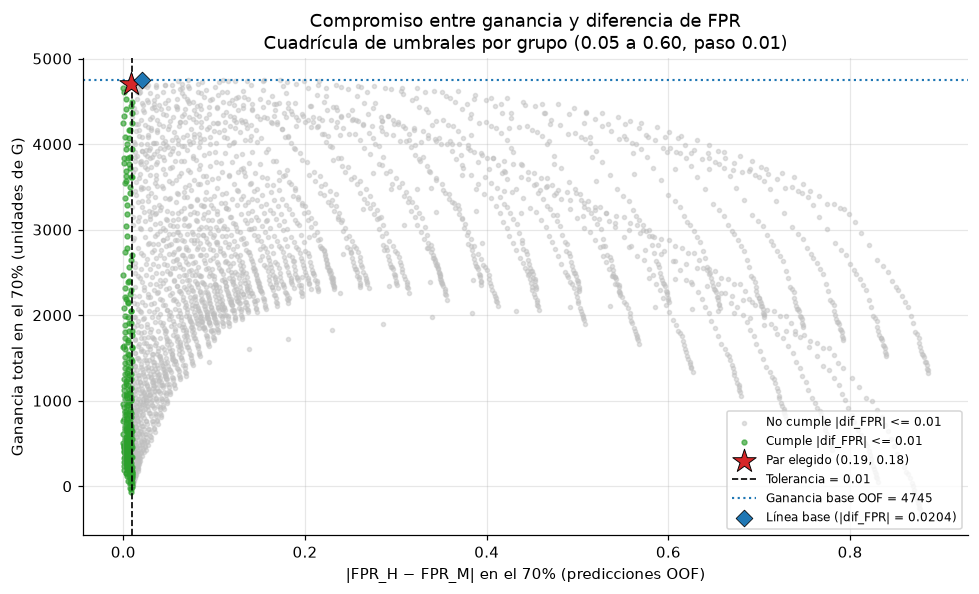

Figura guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/06_ganancia_vs_diferencia.png


In [6]:
pares_grafica = pares_por_definicion[DEFINICION_ELEGIDA].copy()
pares_grafica["abs_dif_FPR"] = pares_grafica["dif_FPR"].abs()
base_oof_dif_fpr = abs(
    eq.diferencia_observada(tabla_base_oof, "FPR")
)

fig, ax = plt.subplots(figsize=(9, 5.5))
no_cumple = pares_grafica.loc[~pares_grafica["cumple"]]
cumple = pares_grafica.loc[pares_grafica["cumple"]]
ax.scatter(
    no_cumple["abs_dif_FPR"],
    no_cumple["ganancia_total"],
    s=7,
    color="0.75",
    alpha=0.45,
    label="No cumple |dif_FPR| <= 0.01",
)
ax.scatter(
    cumple["abs_dif_FPR"],
    cumple["ganancia_total"],
    s=10,
    color="tab:green",
    alpha=0.65,
    label="Cumple |dif_FPR| <= 0.01",
)
ax.scatter(
    [abs(fila_elegida["dif_FPR_oof"])],
    [fila_elegida["ganancia_oof"]],
    marker="*",
    s=260,
    color="tab:red",
    edgecolor="black",
    linewidth=0.6,
    zorder=5,
    label=f"Par elegido ({t_h:.2f}, {t_m:.2f})",
)
ax.axvline(
    TOLERANCIA,
    color="black",
    linestyle="--",
    linewidth=1.1,
    label="Tolerancia = 0.01",
)
ax.axhline(
    ganancia_base_oof,
    color="tab:blue",
    linestyle=":",
    linewidth=1.4,
    label=f"Ganancia base OOF = {ganancia_base_oof:.0f}",
)
ax.scatter(
    [base_oof_dif_fpr],
    [ganancia_base_oof],
    marker="D",
    s=60,
    color="tab:blue",
    edgecolor="black",
    linewidth=0.5,
    zorder=5,
    label=f"Línea base (|dif_FPR| = {base_oof_dif_fpr:.4f})",
)
ax.set_xlabel("|FPR_H − FPR_M| en el 70% (predicciones OOF)")
ax.set_ylabel("Ganancia total en el 70% (unidades de G)")
ax.set_title(
    "Compromiso entre ganancia y diferencia de FPR\n"
    "Cuadrícula de umbrales por grupo (0.05 a 0.60, paso 0.01)"
)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
ruta_grafica_ganancia = RESULTADOS / "06_ganancia_vs_diferencia.png"
fig.savefig(ruta_grafica_ganancia, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: {ruta_grafica_ganancia}")

La nube muestra el compromiso: los pares con diferencia de `FPR` muy pequeña
suelen perder algo de ganancia, y los de mayor ganancia se alejan de la
igualdad. La línea base (rombo azul) queda a la derecha de la tolerancia
(`|dif_FPR| ≈ 0.042`), con una ganancia OOF muy cercana a la del par
elegido. El par elegido (estrella roja) se pega a la frontera de la
tolerancia y conserva casi toda la ganancia: es el mejor intercambio
disponible dentro de la restricción, no un punto arbitrario.

Para entender por qué hacen falta umbrales distintos, conviene ver cómo
cambian `FPR` y `FNR` con el umbral en cada grupo. Si las curvas fueran
idénticas, un solo umbral bastaría para igualar ambas métricas.

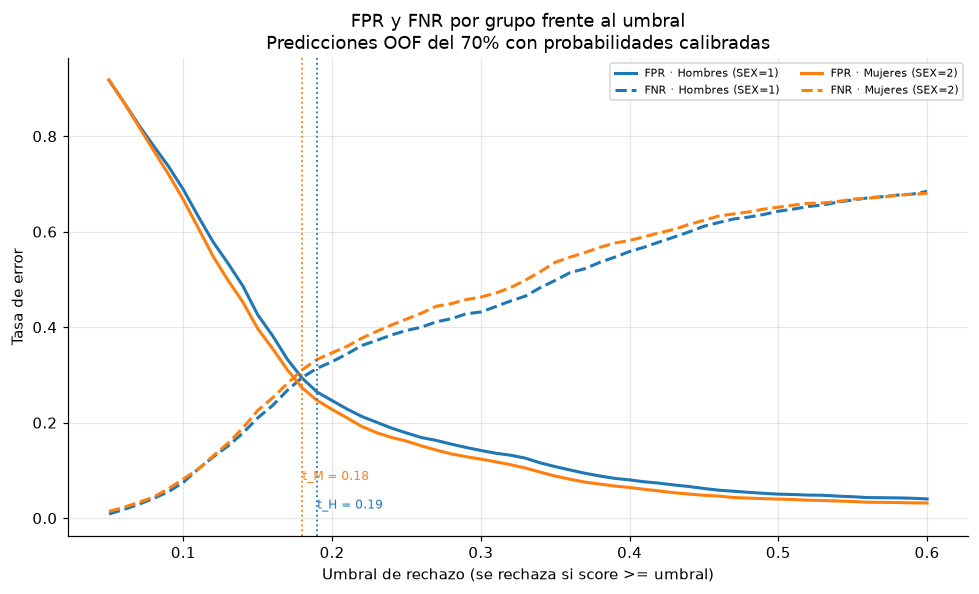

Figura guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/06_metricas_vs_umbral.png


In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for grupo, estilo, color in (
    (eq.GRUPO_HOMBRES, "-", "tab:blue"),
    (eq.GRUPO_MUJERES, "-", "tab:orange"),
):
    sub = tabla_umbrales.loc[tabla_umbrales["grupo"] == grupo]
    ax.plot(
        sub["umbral"],
        sub["FPR"],
        linestyle=estilo,
        color=color,
        linewidth=2,
        label=f"FPR · {grupo}",
    )
    ax.plot(
        sub["umbral"],
        sub["FNR"],
        linestyle="--",
        color=color,
        linewidth=2,
        label=f"FNR · {grupo}",
    )
ax.axvline(t_h, color="tab:blue", linestyle=":", linewidth=1.2)
ax.axvline(t_m, color="tab:orange", linestyle=":", linewidth=1.2)
ax.text(t_h, 0.02, f"t_H = {t_h:.2f}", color="tab:blue", fontsize=8)
ax.text(t_m, 0.08, f"t_M = {t_m:.2f}", color="tab:orange", fontsize=8)
ax.set_xlabel("Umbral de rechazo (se rechaza si score >= umbral)")
ax.set_ylabel("Tasa de error")
ax.set_title(
    "FPR y FNR por grupo frente al umbral\n"
    "Predicciones OOF del 70% con probabilidades calibradas"
)
ax.legend(loc="upper right", fontsize=7, ncol=2)
fig.tight_layout()
ruta_grafica_umbrales = RESULTADOS / "06_metricas_vs_umbral.png"
fig.savefig(ruta_grafica_umbrales, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: {ruta_grafica_umbrales}")

Las curvas confirman que un mismo umbral produce `FPR` y `FNR` distintos en
cada grupo. En la zona de interés, la curva de `FPR` de hombres está por
encima de la de mujeres, y la de `FNR` por debajo: con el umbral único se
rechaza relativamente más a hombres que no incumplen y se dejan pasar
relativamente más incumplidores mujeres. Subir `t_H` a `0.19` y bajar `t_M` a
`0.18` acerca las dos curvas de `FPR` sin mover demasiado la ganancia.

## 6. Tabla antes y después, y costo de ser justo

Se aplica el par `(0.19, 0.18)` al 30% de prueba y se compara con la línea
base. El **costo de equidad** es la ganancia que se deja de obtener:

- en unidades de `G`: `ganancia_base − ganancia_intervención`;
- en porcentaje de la ganancia base;
- por solicitante.

También se reporta el mismo cálculo en OOF, que es donde se eligió el par.

In [8]:
tabla_intervencion_test, avisos_intervencion = eq.tabla_grupos_umbrales(
    y_test, prob_test, sexo_test, t_h, t_m
)
tabla_intervencion_oof, _ = eq.tabla_grupos_umbrales(
    y_train.to_numpy(), oof, sexo_train, t_h, t_m
)

filas_antes_despues = []
for grupo in (eq.GRUPO_HOMBRES, eq.GRUPO_MUJERES, eq.GRUPO_TODOS):
    antes = tabla_base_test.loc[tabla_base_test["grupo"] == grupo].iloc[0]
    despues = tabla_intervencion_test.loc[
        tabla_intervencion_test["grupo"] == grupo
    ].iloc[0]
    filas_antes_despues.append(
        {
            "grupo": grupo,
            "n": int(antes["n"]),
            "tasa_rechazo_antes": float(antes["tasa_rechazo"]),
            "tasa_rechazo_despues": float(despues["tasa_rechazo"]),
            "delta_tasa_rechazo": float(
                despues["tasa_rechazo"] - antes["tasa_rechazo"]
            ),
            "PPV_antes": float(antes["PPV"]),
            "PPV_despues": float(despues["PPV"]),
            "delta_PPV": float(despues["PPV"] - antes["PPV"]),
            "FPR_antes": float(antes["FPR"]),
            "FPR_despues": float(despues["FPR"]),
            "delta_FPR": float(despues["FPR"] - antes["FPR"]),
            "FNR_antes": float(antes["FNR"]),
            "FNR_despues": float(despues["FNR"]),
            "delta_FNR": float(despues["FNR"] - antes["FNR"]),
            "ganancia_antes": float(antes["ganancia"]),
            "ganancia_despues": float(despues["ganancia"]),
            "delta_ganancia": float(despues["ganancia"] - antes["ganancia"]),
            "ganancia_por_solicitante_antes": float(
                antes["ganancia_por_solicitante"]
            ),
            "ganancia_por_solicitante_despues": float(
                despues["ganancia_por_solicitante"]
            ),
        }
    )

antes_despues = pd.DataFrame(filas_antes_despues)
display(
    antes_despues[
        [
            "grupo",
            "n",
            "FPR_antes",
            "FPR_despues",
            "delta_FPR",
            "FNR_antes",
            "FNR_despues",
            "delta_FNR",
            "PPV_antes",
            "PPV_despues",
            "delta_PPV",
            "tasa_rechazo_antes",
            "tasa_rechazo_despues",
            "delta_tasa_rechazo",
            "ganancia_antes",
            "ganancia_despues",
            "delta_ganancia",
        ]
    ].round(6)
)
antes_despues.to_csv(
    RESULTADOS / "06_antes_despues.csv",
    index=False,
    float_format="%.8f",
)

ganancia_intervencion_test = float(
    tabla_intervencion_test.loc[
        tabla_intervencion_test["grupo"] == eq.GRUPO_TODOS, "ganancia"
    ].iloc[0]
)
ganancia_intervencion_oof = float(
    tabla_intervencion_oof.loc[
        tabla_intervencion_oof["grupo"] == eq.GRUPO_TODOS, "ganancia"
    ].iloc[0]
)

costo = pd.DataFrame(
    [
        {
            "conjunto": "prueba (30%)",
            "ganancia_base": ganancia_base_test,
            "ganancia_intervencion": ganancia_intervencion_test,
            "perdida_unidades_G": ganancia_base_test
            - ganancia_intervencion_test,
            "perdida_pct": 100.0
            * (ganancia_base_test - ganancia_intervencion_test)
            / ganancia_base_test,
            "ganancia_base_por_solicitante": ganancia_base_test / len(y_test),
            "ganancia_intervencion_por_solicitante": ganancia_intervencion_test
            / len(y_test),
            "perdida_por_solicitante": (
                ganancia_base_test - ganancia_intervencion_test
            )
            / len(y_test),
        },
        {
            "conjunto": "OOF (70%)",
            "ganancia_base": ganancia_base_oof,
            "ganancia_intervencion": ganancia_intervencion_oof,
            "perdida_unidades_G": ganancia_base_oof
            - ganancia_intervencion_oof,
            "perdida_pct": 100.0
            * (ganancia_base_oof - ganancia_intervencion_oof)
            / ganancia_base_oof,
            "ganancia_base_por_solicitante": ganancia_base_oof / len(y_train),
            "ganancia_intervencion_por_solicitante": ganancia_intervencion_oof
            / len(y_train),
            "perdida_por_solicitante": (
                ganancia_base_oof - ganancia_intervencion_oof
            )
            / len(y_train),
        },
    ]
)
display(costo.round(6))
costo.to_csv(
    RESULTADOS / "06_costo_equidad.csv",
    index=False,
    float_format="%.8f",
)

print(
    "Costo en prueba: "
    f"{ganancia_base_test - ganancia_intervencion_test:.0f} unidades de G "
    f"({100.0 * (ganancia_base_test - ganancia_intervencion_test) / ganancia_base_test:.4f}% "
    "de la ganancia base)."
)
print(
    "Costo por solicitante en prueba: "
    f"{(ganancia_base_test - ganancia_intervencion_test) / len(y_test):.6f} G."
)
if avisos_intervencion:
    print("AVISOS de división entre cero en la intervención:")
    for aviso in avisos_intervencion:
        print(f"  - {aviso}")
else:
    print("Sin divisiones entre cero en la intervención.")

,grupo,n,FPR_antes,FPR_despues,delta_FPR,FNR_antes,FNR_despues,delta_FNR,PPV_antes,PPV_despues,delta_PPV,tasa_rechazo_antes,tasa_rechazo_despues,delta_tasa_rechazo,ganancia_antes,ganancia_despues,delta_ganancia
0,Hombres (SEX=1),3584,0.367406,0.274282,-0.093125,0.250299,0.320958,0.070659,0.382641,0.429220,0.046580,0.456473,0.368583,-0.087891,694.0,655.0,-39.0
1,Mujeres (SEX=2),5416,0.325117,0.264789,-0.060329,0.274221,0.313149,0.038927,0.377248,0.413111,0.035863,0.410635,0.354874,-0.055761,1290.0,1322.0,32.0
2,Todos,9000,0.341704,0.268512,-0.073192,0.264189,0.316424,0.052235,0.379534,0.419673,0.040139,0.428889,0.360333,-0.068556,1984.0,1977.0,-7.0


,conjunto,ganancia_base,ganancia_intervencion,perdida_unidades_G,perdida_pct,ganancia_base_por_solicitante,ganancia_intervencion_por_solicitante,perdida_por_solicitante
0,prueba (30%),1984.0,1977.0,7.0,0.352823,0.220444,0.219667,0.000778
1,OOF (70%),4745.0,4697.0,48.0,1.011591,0.225952,0.223667,0.002286


Costo en prueba: 7 unidades de G (0.3528% de la ganancia base).
Costo por solicitante en prueba: 0.000778 G.
Sin divisiones entre cero en la intervención.


La intervención **igual FPR** reduce la diferencia de `FPR` en prueba de
`0.042289` a `0.009493`, pero no la elimina del todo: la tolerancia se
cumplió en OOF, no necesariamente en una muestra nueva. A cambio, la
diferencia de `FNR` pasa de `-0.023922` a `0.007809`, también pequeña. La
ganancia baja de `1984` a `1977` unidades de `G`: `7` unidades, `0.3528%` de
la ganancia base, o `0.000778` por solicitante. En OOF el costo es mayor:
`48` unidades (`1.0116%`), porque ahí se eligió el par y la restricción de
equidad se cumple con más holgura. Esa diferencia entre OOF y prueba es
esperable: el par se optimizó en OOF, no en la muestra de reporte.

Las otras definiciones no son gratuitas: la paridad demográfica y la
predictiva hasta suben la ganancia de prueba (`+11` y `+35`), pero dejan
diferencias de `FPR` y `FNR` mayores. Igualar `PPV` no es una meta de
equidad de errores; es otra definición, y el banco debe elegir cuál quiere
defender.

## 7. Bootstrap de la diferencia de `FPR` después de intervenir

Se remuestrean las 9,000 filas de prueba con reemplazo, se aplica el mismo
par `(0.19, 0.18)` en cada réplica y se recalcula `FPR_H − FPR_M`. El
intervalo del 95% se obtiene por percentiles. También se hace un bootstrap
de la diferencia de ganancia `intervención − base` para juzgar si el costo
de `7` unidades es distinguible del ruido.

In [9]:
rechazo_intervencion = np.where(
    sexo_test == 1, prob_test >= t_h, prob_test >= t_m
)
replicas_intervencion, replicas_invalidas = eq.bootstrap_diferencias(
    y_test,
    rechazo_intervencion,
    sexo_test,
    metricas=("FPR", "FNR"),
    n_boot=N_BOOTSTRAP,
    seed=SEED,
)

filas_bootstrap = []
for metrica in ("FPR", "FNR"):
    observada = eq.diferencia_observada(tabla_intervencion_test, metrica)
    filas_bootstrap.append(
        eq.resumen_bootstrap(
            f"{metrica}_H - {metrica}_M (después)",
            observada,
            replicas_intervencion[metrica],
            N_BOOTSTRAP,
        )
    )
tabla_bootstrap = pd.DataFrame(filas_bootstrap)
display(tabla_bootstrap.round(6))
tabla_bootstrap.to_csv(
    RESULTADOS / "06_bootstrap_ic95.csv",
    index=False,
    float_format="%.8f",
)

pd.DataFrame(
    {
        "replica": np.arange(1, N_BOOTSTRAP + 1),
        "dif_FPR_H_menos_FPR_M": replicas_intervencion["FPR"],
        "dif_FNR_H_menos_FNR_M": replicas_intervencion["FNR"],
    }
).to_csv(
    RESULTADOS / "06_bootstrap_replicas.csv",
    index=False,
    float_format="%.8f",
)

# Bootstrap de la diferencia de ganancia. Se usa un generador propio con la
# misma semilla para que el resultado no dependa de otras llamadas aleatorias.
rng_ganancia = np.random.default_rng(SEED)
n_test = len(y_test)
diferencias_ganancia = np.empty(N_BOOTSTRAP, dtype=float)
for b in range(N_BOOTSTRAP):
    indices_b = rng_ganancia.integers(0, n_test, size=n_test)
    y_b = y_test[indices_b]
    prob_b = prob_test[indices_b]
    sexo_b = sexo_test[indices_b]
    rechazo_base_b = prob_b >= UMBRAL
    rechazo_int_b = np.where(
        sexo_b == 1, prob_b >= t_h, prob_b >= t_m
    )
    ganancia_base_b = (
        G * np.sum((y_b == 0) & ~rechazo_base_b)
        - L * np.sum((y_b == 1) & ~rechazo_base_b)
    )
    ganancia_int_b = (
        G * np.sum((y_b == 0) & ~rechazo_int_b)
        - L * np.sum((y_b == 1) & ~rechazo_int_b)
    )
    diferencias_ganancia[b] = ganancia_int_b - ganancia_base_b

dif_ganancia_observada = ganancia_intervencion_test - ganancia_base_test
resumen_ganancia = eq.resumen_bootstrap(
    "ganancia_intervención - ganancia_base",
    dif_ganancia_observada,
    diferencias_ganancia,
    N_BOOTSTRAP,
)
tabla_bootstrap_ganancia = pd.DataFrame([resumen_ganancia])
display(tabla_bootstrap_ganancia.round(6))
tabla_bootstrap_ganancia.to_csv(
    RESULTADOS / "06_bootstrap_ganancia.csv",
    index=False,
    float_format="%.8f",
)

print(
    f"Réplicas bootstrap inválidas (FPR/FNR): {replicas_invalidas} "
    f"de {N_BOOTSTRAP}."
)
print(
    "Diferencia de ganancia observada: "
    f"{dif_ganancia_observada:.0f} unidades de G."
)

,diferencia,observada,media_bootstrap,sd_bootstrap,ic95_inferior,ic95_superior,contiene_cero,replicas_validas,replicas_invalidas
0,FPR_H - FPR_M (después),0.009493,0.009313,0.011004,-0.012185,0.031146,sí,2000,0
1,FNR_H - FNR_M (después),0.007809,0.008121,0.021369,-0.034175,0.049182,sí,2000,0


,diferencia,observada,media_bootstrap,sd_bootstrap,ic95_inferior,ic95_superior,contiene_cero,replicas_validas,replicas_invalidas
0,ganancia_intervención - ganancia_base,-7.0,-7.8415,54.740466,-116.0,100.025,sí,2000,0


Réplicas bootstrap inválidas (FPR/FNR): 0 de 2000.
Diferencia de ganancia observada: -7 unidades de G.


Después de intervenir, la diferencia de `FPR` es `0.009493` y su IC 95% es
`[-0.012185, 0.031146]`: **contiene el cero**. Ya no se puede afirmar que la
diferencia sea distinta de cero con esta muestra. La diferencia de `FNR` es
`0.007809`, IC `[-0.034175, 0.049182]`, también compatible con cero. La
diferencia de ganancia es `-7` unidades, IC `[-116, 100.025]`: el costo es
pequeño frente a la incertidumbre y no se distingue de cero. Eso no
significa que la intervención sea gratis en todos los escenarios; significa
que, con 9,000 solicitantes, su costo esperado es bajo y la evidencia no
permite afirmar que sea distinto de cero.

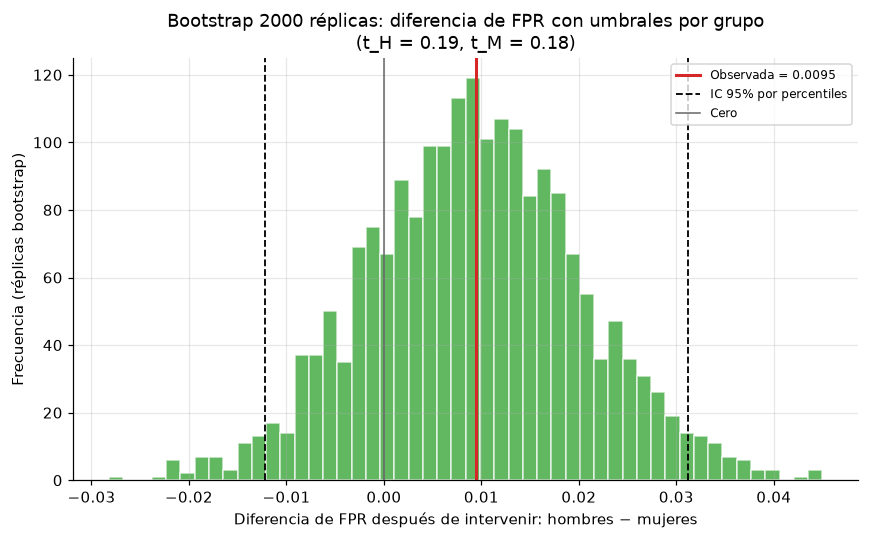

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    replicas_intervencion["FPR"][
        np.isfinite(replicas_intervencion["FPR"])
    ],
    bins=50,
    color="tab:green",
    alpha=0.75,
    edgecolor="white",
)
ax.axvline(
    eq.diferencia_observada(tabla_intervencion_test, "FPR"),
    color="tab:red",
    linewidth=2,
    label=(
        "Observada = "
        f"{eq.diferencia_observada(tabla_intervencion_test, 'FPR'):.4f}"
    ),
)
ax.axvline(
    tabla_bootstrap.loc[0, "ic95_inferior"],
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="IC 95% por percentiles",
)
ax.axvline(
    tabla_bootstrap.loc[0, "ic95_superior"],
    color="black",
    linestyle="--",
    linewidth=1.2,
)
ax.axvline(0.0, color="0.4", linewidth=1.0, label="Cero")
ax.set_xlabel("Diferencia de FPR después de intervenir: hombres − mujeres")
ax.set_ylabel("Frecuencia (réplicas bootstrap)")
ax.set_title(
    "Bootstrap 2000 réplicas: diferencia de FPR con umbrales por grupo\n"
    f"(t_H = {t_h:.2f}, t_M = {t_m:.2f})"
)
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
ruta_hist_fpr = RESULTADOS / "06_hist_fpr_despues.png"
fig.savefig(ruta_hist_fpr, bbox_inches="tight")
plt.show()

El histograma de la diferencia de `FPR` después de intervenir está centrado
cerca de `0.009` y el IC cruza el cero de forma amplia. La masa ya no está
casi toda a la derecha como en la línea base de 05. Esa es la evidencia
visual de que la intervención redujo la disparidad a un tamaño que la
muestra no distingue del ruido. La figura se guardó en
`resultados/06_hist_fpr_despues.png`.

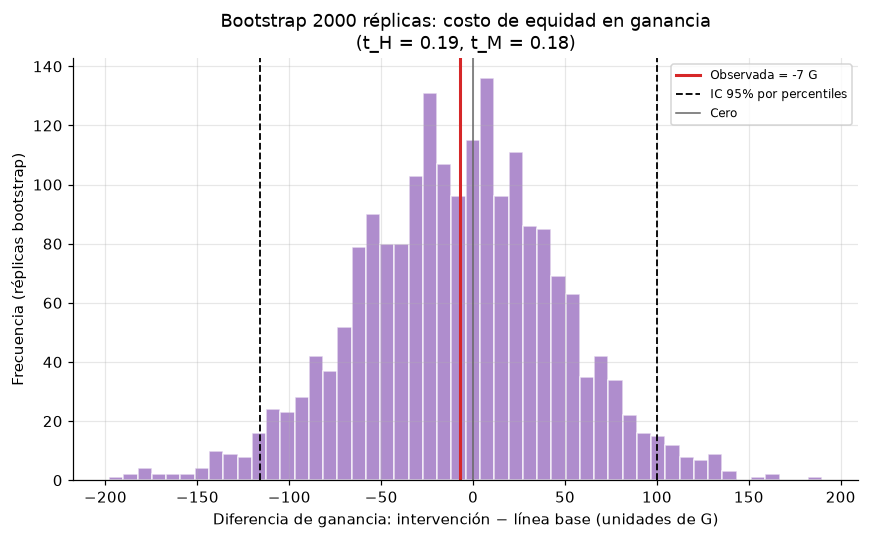

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    diferencias_ganancia,
    bins=50,
    color="tab:purple",
    alpha=0.75,
    edgecolor="white",
)
ax.axvline(
    dif_ganancia_observada,
    color="tab:red",
    linewidth=2,
    label=f"Observada = {dif_ganancia_observada:.0f} G",
)
ax.axvline(
    tabla_bootstrap_ganancia.loc[0, "ic95_inferior"],
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="IC 95% por percentiles",
)
ax.axvline(
    tabla_bootstrap_ganancia.loc[0, "ic95_superior"],
    color="black",
    linestyle="--",
    linewidth=1.2,
)
ax.axvline(0.0, color="0.4", linewidth=1.0, label="Cero")
ax.set_xlabel("Diferencia de ganancia: intervención − línea base (unidades de G)")
ax.set_ylabel("Frecuencia (réplicas bootstrap)")
ax.set_title(
    "Bootstrap 2000 réplicas: costo de equidad en ganancia\n"
    f"(t_H = {t_h:.2f}, t_M = {t_m:.2f})"
)
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
ruta_hist_ganancia = RESULTADOS / "06_hist_ganancia_despues.png"
fig.savefig(ruta_hist_ganancia, bbox_inches="tight")
plt.show()

La distribución del cambio de ganancia está centrada en `-7` unidades y es
ancha: el IC va de `-116` a `+100`. El costo puntual es pequeño, pero la
incertidumbre es del orden de cien unidades de `G`. Para el banco, eso
significa que la política de igualar `FPR` no compromete de forma apreciable
la ganancia esperada con este tamaño de muestra, aunque conviene monitorear
el resultado en carteras nuevas.

## 8. Qué pasó con las otras definiciones

La tabla siguiente resume el resultado de las cinco definiciones en prueba.
Sirve para comparar el costo y la disparidad que deja cada una.

In [12]:
resumen_definiciones = comparativa[
    [
        "definicion",
        "factible",
        "t_H",
        "t_M",
        "dif_FPR_oof",
        "dif_FNR_oof",
        "dif_FPR_test",
        "dif_FNR_test",
        "dif_PPV_test",
        "ganancia_test",
        "delta_ganancia_test",
        "pct_perdida_test",
    ]
].copy()
display(resumen_definiciones.round(6))
resumen_definiciones.to_csv(
    RESULTADOS / "06_resumen_definiciones.csv",
    index=False,
    float_format="%.8f",
)

,definicion,factible,t_H,t_M,dif_FPR_oof,dif_FNR_oof,dif_FPR_test,dif_FNR_test,dif_PPV_test,ganancia_test,delta_ganancia_test,pct_perdida_test
0,Paridad demográfica (igual tasa de rechazo),sí,0.18,0.17,-0.017647,0.012580,0.003792,0.005751,0.022149,1995.0,11.0,-0.554435
1,Igual FPR,sí,0.19,0.18,-0.008511,0.002948,0.009493,0.007809,0.016109,1977.0,-7.0,0.352823
2,Igual FNR,sí,0.19,0.18,-0.008511,0.002948,0.009493,0.007809,0.016109,1977.0,-7.0,0.352823
3,Igual FPR y FNR,sí,0.19,0.18,-0.008511,0.002948,0.009493,0.007809,0.016109,1977.0,-7.0,0.352823
4,Paridad predictiva (igual PPV),sí,0.16,0.18,0.109587,-0.075070,0.123352,-0.077221,-0.038918,2019.0,35.0,-1.764113


- **Paridad demográfica** (`0.18, 0.17`): iguala la tasa de rechazo en OOF,
  pero deja `dif_FPR` y `dif_FNR` de aproximadamente `1.8` y `1.3` puntos
  porcentuales en OOF. En prueba hasta sube la ganancia (`+11`), pero no
  corrige la disparidad de errores que el bootstrap de 05 señaló como real.
- **Igual `FNR`** (`0.19, 0.18`): elige el mismo par que igual `FPR`. La
  diferencia de `FNR` base era compatible con cero, así que no se gana nada
  adicional en la práctica.
- **Igual `FPR` y `FNR`** (`0.19, 0.18`): también elige el mismo par. Es la
  opción más exigente, pero la cuadrícula no encuentra un par que mejore
  simultáneamente ambas métricas más allá de lo que ya logra igual `FPR`.
- **Paridad predictiva** (`0.16, 0.18`): iguala la `PPV` y sube la ganancia
  (`+35`), pero deja `dif_FPR = 0.109587` y `dif_FNR = -0.075070` en OOF. Es
  la que peor trata la disparidad de errores.

Conclusión: no hay una definición que sea gratuita y que además iguale todo.
Igual `FPR` es la que mejor se alinea con la evidencia de 05 y la que menos
compromete la ganancia entre las que atacan la disparidad real.

## 9. Cierre del inciso (d)

- La línea base con umbral único `1/6` produce una ganancia de prueba de
  `1984` unidades de `G` y una diferencia de `FPR` de `0.042289`, que el
  bootstrap de 05 mostró como real.
- Se evaluaron las cinco definiciones con una cuadrícula de `0.05` a `0.60`
  y tolerancia `0.01`. Igual `FPR`, igual `FNR` e igual `FPR` y `FNR` eligen
  el mismo par `(0.19, 0.18)`; paridad demográfica elige `(0.18, 0.17)` y
  paridad predictiva `(0.16, 0.18)`.
- La definición elegida es **igual `FPR`**, porque es la disparidad que la
  evidencia de 05 respalda y porque el par elegido conserva casi toda la
  ganancia.
- La intervención reduce la diferencia de `FPR` de `0.042289` a `0.009493`
  en prueba; su IC 95% `[-0.012185, 0.031146]` contiene el cero.
- El costo es `7` unidades de `G` (`0.3528%` de la ganancia base,
  `0.000778` por solicitante); el IC bootstrap de la diferencia de ganancia
  `[-116, 100.025]` también contiene el cero.
- Los umbrales se eligieron solo con OOF; la prueba se usó para reportar, no
  para afinar. Las tablas y figuras quedaron en `resultados/06_*`.